<a href="https://colab.research.google.com/github/Ashilas/BookMYStay/blob/main/mlproject.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [25]:
from google.colab import files
uploaded=files.upload()

# The file 'Car Sales.xlsx - car_data (1).csv' is already uploaded.
# uploaded = files.upload()

Saving Car Sales.xlsx - car_data.csv to Car Sales.xlsx - car_data (1).csv


In [26]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler

df = pd.read_csv("Car Sales.xlsx - car_data.csv")

print(df.head())
print(df.info())
print(df.isnull().sum())

df.drop_duplicates(inplace=True)

encoder = LabelEncoder()

for col in df.select_dtypes(include="object").columns:
    df[col] = encoder.fit_transform(df[col].astype(str))

X = df.drop("Price ($)", axis=1)
y = df["Price ($)"]

scaler = StandardScaler()
X = scaler.fit_transform(X)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(X_train.shape)
print(X_test.shape)

         Car_id      Date Customer Name Gender  Annual Income  \
0  C_CND_000001  1/2/2022     Geraldine   Male          13500   
1  C_CND_000002  1/2/2022           Gia   Male        1480000   
2  C_CND_000003  1/2/2022        Gianna   Male        1035000   
3  C_CND_000004  1/2/2022       Giselle   Male          13500   
4  C_CND_000005  1/2/2022         Grace   Male        1465000   

                           Dealer_Name   Company       Model  \
0  Buddy Storbeck's Diesel Service Inc      Ford  Expedition   
1                     C & M Motors Inc     Dodge     Durango   
2                          Capitol KIA  Cadillac    Eldorado   
3               Chrysler of Tri-Cities    Toyota      Celica   
4                    Chrysler Plymouth     Acura          TL   

                      Engine Transmission       Color  Price ($)  Dealer_No   \
0  DoubleÂ Overhead Camshaft         Auto       Black      26000  06457-3834   
1  DoubleÂ Overhead Camshaft         Auto       Black      19000

In [27]:
#t2

R2 Score: 0.005262805424133266
Mean Squared Error: 210557891.64910418


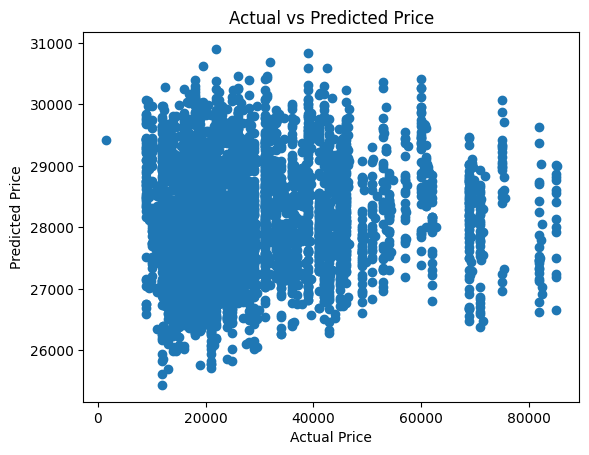

In [28]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
import matplotlib.pyplot as plt

model = LinearRegression()

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("R2 Score:", r2_score(y_test, y_pred))
print("Mean Squared Error:", mean_squared_error(y_test, y_pred))

plt.scatter(y_test, y_pred)
plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted Price")
plt.show()


In [29]:
import pandas as pd

pd.set_option('display.max_columns', None)
pd.set_option('display.width', None)
pd.set_option('display.max_colwidth', None)

print(df.head())

   Car_id  Date  Customer Name  Gender  Annual Income  Dealer_Name  Company  \
0       0    11           1050       1          13500            0        8   
1       1    11           1057       1        1480000            1        7   
2       2    11           1061       1        1035000            2        4   
3       3    11           1068       1          13500            4       27   
4       4    11           1083       1        1465000            3        0   

   Model  Engine  Transmission  Color  Price ($)  Dealer_No   Body Style  \
0     60       0             0      0      26000           0           3   
1     52       0             0      0      19000           3           3   
2     57       1             1      2      31500           1           2   
3     36       1             1      1      14000           6           3   
4    141       0             0      2      24500           2           1   

     Phone  Dealer_Region  
0  8264678              4  
1  6848189  

R2 Score: 0.005262805424133266
Mean Squared Error: 210557891.64910418


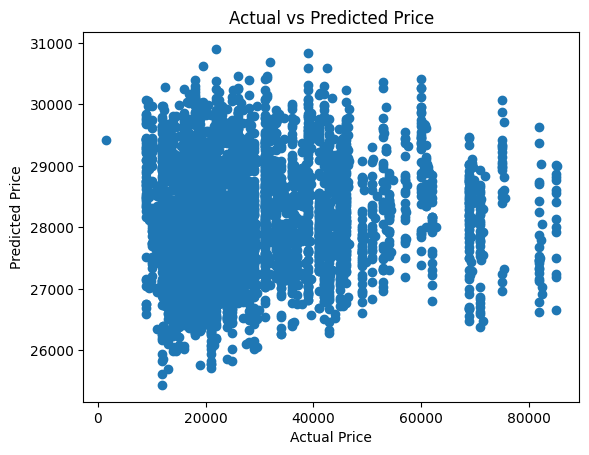

In [30]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
import matplotlib.pyplot as plt

model = LinearRegression()

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("R2 Score:", r2_score(y_test, y_pred))
print("Mean Squared Error:", mean_squared_error(y_test, y_pred))

plt.scatter(y_test, y_pred)
plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted Price")
plt.show()


In [31]:
#t3

In [33]:
import pandas as pd
import numpy as np

df = pd.read_csv("Car Sales.xlsx - car_data.csv")

print(df.head())
print(df.shape)
print(df.info())

         Car_id      Date Customer Name Gender  Annual Income  \
0  C_CND_000001  1/2/2022     Geraldine   Male          13500   
1  C_CND_000002  1/2/2022           Gia   Male        1480000   
2  C_CND_000003  1/2/2022        Gianna   Male        1035000   
3  C_CND_000004  1/2/2022       Giselle   Male          13500   
4  C_CND_000005  1/2/2022         Grace   Male        1465000   

                           Dealer_Name   Company       Model  \
0  Buddy Storbeck's Diesel Service Inc      Ford  Expedition   
1                     C & M Motors Inc     Dodge     Durango   
2                          Capitol KIA  Cadillac    Eldorado   
3               Chrysler of Tri-Cities    Toyota      Celica   
4                    Chrysler Plymouth     Acura          TL   

                      Engine Transmission       Color  Price ($)  Dealer_No   \
0  DoubleÂ Overhead Camshaft         Auto       Black      26000  06457-3834   
1  DoubleÂ Overhead Camshaft         Auto       Black      19000

In [34]:
df = df.dropna()

print(df.shape)

(23905, 16)


In [35]:
numeric_df = df.select_dtypes(include=np.number)

print(numeric_df.columns)

Index(['Annual Income', 'Price ($)', 'Phone'], dtype='object')


In [36]:
X = numeric_df.drop("Price ($)", axis=1)
y = numeric_df["Price ($)"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (23905, 2)
y shape: (23905,)


In [37]:
from sklearn.model_selection import KFold, cross_val_score
from sklearn.linear_model import LinearRegression

model = LinearRegression()

kf = KFold(n_splits=5, shuffle=True, random_state=42)

scores = cross_val_score(
    model,
    X,
    y,
    cv=kf,
    scoring="r2"
)

print("Cross Validation Scores:")
print(scores)

print("Average R2 Score:", scores.mean())
print("Standard Deviation:", scores.std())

Cross Validation Scores:
[ 5.53494918e-06  3.69386984e-04 -1.45354534e-03 -1.82459267e-04
  2.83767538e-04]
Average R2 Score: -0.0001954630269325186
Standard Deviation: 0.0006590990603808177


In [38]:
for i, score in enumerate(scores, 1):
    print("Fold", i, "R2 Score:", score)

print("Average R2 Score:", scores.mean())

Fold 1 R2 Score: 5.534949177543602e-06
Fold 2 R2 Score: 0.0003693869840389885
Fold 3 R2 Score: -0.0014535453388506703
Fold 4 R2 Score: -0.000182459267008106
Fold 5 R2 Score: 0.00028376753797965115
Average R2 Score: -0.0001954630269325186


In [39]:
#t4

In [40]:
import pandas as pd
import numpy as np

df = pd.read_csv("Car Sales.xlsx - car_data.csv")

df = df.dropna()

numeric_df = df.select_dtypes(include=np.number)

print(numeric_df.head())

   Annual Income  Price ($)    Phone
0          13500      26000  8264678
1        1480000      19000  6848189
2        1035000      31500  7298798
3          13500      14000  6257557
4        1465000      24500  7081483


In [41]:
X = numeric_df.drop('Price ($)', axis=1)
y = numeric_df['Price ($)']

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (23905, 2)
y shape: (23905,)


In [42]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (19124, 2)
Testing data: (4781, 2)


In [43]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

In [44]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Mean Absolute Error:", mae)
print("Mean Squared Error:", mse)
print("Root Mean Squared Error:", rmse)
print("R2 Score:", r2)

Mean Absolute Error: 11118.237696313961
Mean Squared Error: 210597462.0884982
Root Mean Squared Error: 14511.976505235192
R2 Score: 5.5349491776546245e-06


In [45]:
#t5

In [46]:
import pandas as pd
import numpy as np

df = pd.read_csv("Car Sales.xlsx - car_data.csv")

df = df.dropna()

numeric_df = df.select_dtypes(include=np.number)

X = numeric_df.drop('Price ($)', axis=1)
y = numeric_df['Price ($)']

print("Independent variables:")
print(X.columns)

print("\nTarget variable:")
print("Price ($)")

Independent variables:
Index(['Annual Income', 'Phone'], dtype='object')

Target variable:
Price ($)


In [47]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (19124, 2)
Testing data: (4781, 2)


In [48]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Model trained successfully")

Model trained successfully


In [49]:
print("Intercept:", model.intercept_)

for column, coefficient in zip(X.columns, model.coef_):
    print(column, ":", coefficient)

Intercept: 28178.390439307208
Annual Income : 0.00022774034802430928
Phone : -3.1354917114017614e-05


In [50]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

MAE: 11118.237696313961
MSE: 210597462.0884982
RMSE: 14511.976505235192
R2 Score: 5.5349491776546245e-06


In [51]:
#t6

In [52]:
import pandas as pd
import numpy as np

df = pd.read_csv("Car Sales.xlsx - car_data.csv")

df = df.dropna()

numeric_df = df.select_dtypes(include=np.number)

print(numeric_df.head())

   Annual Income  Price ($)    Phone
0          13500      26000  8264678
1        1480000      19000  6848189
2        1035000      31500  7298798
3          13500      14000  6257557
4        1465000      24500  7081483


In [53]:
median_price = numeric_df['Price ($)'].median()

numeric_df['Price_Category'] = (
    numeric_df['Price ($)'] >= median_price
).astype(int)

print("Median Price:", median_price)

print(numeric_df[['Price ($)', 'Price_Category']].head())

Median Price: 23000.0
   Price ($)  Price_Category
0      26000               1
1      19000               0
2      31500               1
3      14000               0
4      24500               1


In [54]:
X = numeric_df.drop(['Price ($)', 'Price_Category'], axis=1)

y = numeric_df['Price_Category']

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (23905, 2)
y shape: (23905,)


In [55]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (19124, 2)
Testing data: (4781, 2)


In [56]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [57]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression()

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Logistic Regression completed")

Logistic Regression completed


In [58]:
from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)

Accuracy: 0.499895419368333
Precision: 0.501621271076524
Recall: 0.6443148688046647
F1 Score: 0.5640838650865998


In [59]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[ 843 1537]
 [ 854 1547]]


In [61]:
#t7

Explained variance: [0.50017703 0.49982297]
Total variance: 1.0


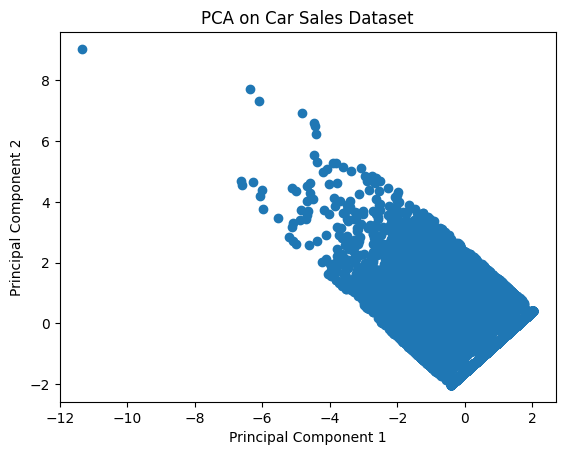

In [62]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Fixed: Added the missing closing single quote
filename = "Car Sales.xlsx - car_data.csv"

# Fixed: Read the CSV file into 'df' first before calling dropna()
df = pd.read_csv(filename)
df = df.dropna()

X = df.select_dtypes(include=np.number)
X = X.drop(columns=["Price ($)"], errors="ignore")
X = X.replace([np.inf, -np.inf], np.nan)
X = X.dropna(axis=1, how="all")

X = SimpleImputer(strategy="median").fit_transform(X)

if X.shape[1] < 2:
    print("PCA needs at least two numeric columns.")
else:
    X_scaled = StandardScaler().fit_transform(X)

    pca = PCA(n_components=2)
    X_pca = pca.fit_transform(X_scaled)

    print("Explained variance:", pca.explained_variance_ratio_)
    print("Total variance:", sum(pca.explained_variance_ratio_))

    plt.scatter(X_pca[:, 0], X_pca[:, 1])
    plt.xlabel("Principal Component 1")
    plt.ylabel("Principal Component 2")
    plt.title("PCA on Car Sales Dataset")
    plt.show()

In [ ]:
#t8

In [63]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, classification_report

df = pd.read_csv("Car Sales.xlsx - car_data.csv")
df = df.dropna()

y = pd.qcut(df["Price ($)"], q=3, labels=[0, 1, 2])

X = df.select_dtypes(include="number")
X = X.drop(columns=["Price ($)"], errors="ignore")

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = GaussianNB()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

Accuracy: 0.3440702781844802
              precision    recall  f1-score   support

           0       0.35      0.89      0.50      1652
           1       0.15      0.00      0.00      1605
           2       0.33      0.11      0.17      1524

    accuracy                           0.34      4781
   macro avg       0.28      0.33      0.22      4781
weighted avg       0.28      0.34      0.23      4781



In [ ]:
#t9

In [64]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report

df = pd.read_csv("Car Sales.xlsx - car_data.csv")
df = df.dropna()

y = pd.qcut(df["Price ($)"], q=3, labels=[0, 1, 2])

X = df.select_dtypes(include="number")
X = X.drop(columns=["Price ($)"], errors="ignore")

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

model = SVC(kernel="linear")
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

Accuracy: 0.34553440702781846
              precision    recall  f1-score   support

           0       0.35      1.00      0.51      1652
           1       0.00      0.00      0.00      1605
           2       0.00      0.00      0.00      1524

    accuracy                           0.35      4781
   macro avg       0.12      0.33      0.17      4781
weighted avg       0.12      0.35      0.18      4781



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
